### 1. Во вкладке "Данные об аудитории" информация о пользователях, посетивших наше приложение в ноябре. Чему равен MAU продукта? 
 #### 7639 
 #### 16814 
 #### 10482 
 #### 16529

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel('test_data.xlsx')
df.head(10)

,date,user_id,view_adverts
0,2023-11-11,8c020470-8461-11ed-83d0-552e8cc749d6,13
1,2023-11-18,5875f070-7b92-11ee-a6fb-8b298e83f4f7,14
2,2023-11-29,3c2d27c0-4fd6-11eb-b89f-2ffb31b67dd6,21
3,2023-11-29,234a96d0-ad16-11ed-a2e6-793ddfeeba1f,23
4,2023-11-29,4d07c180-644f-11eb-879c-b7c02edf4f37,12
5,2023-11-12,059ec300-810e-11ee-b433-b1c037ab56d3,12
6,2023-11-08,4cedb770-1174-11ee-b5d1-5190f485ef48,26
7,2023-11-01,2f35ccf0-796b-11ed-96d9-2b24e5ad01fb,12
8,2023-11-01,ef6eb4d0-01bd-11ed-ab09-b1117ba72e2f,15
9,2023-11-01,17ce4000-77db-11ee-a3a0-edfd72e146b8,13


In [4]:
mau = df['user_id'].nunique()

print('MAU:', mau)

MAU: 7639


### 2. Используя вкладку "Данные об аудитории", посчитайте, чему будет равен DAU
 #### 255 
 #### 490
 #### 560
 #### 483

In [7]:
# DAU за каждый день
dau_check = (
    november.groupby(november['date'].dt.date)['user_id']
    .nunique()
)

print('Средний DAU:', dau_check.mean())

Средний DAU: 560.4666666666667


### 3. Используя вкладку "Данные об аудитории", посчитайте, чему будет равен retention первого дня у пользователей, пришедших в продукт 1 ноября 
 #### 28,3% 
 #### 26,6% 
 #### 38,5% 
 #### 32,7%

In [9]:
# Пользователи 1 ноября
users_day0 = set(
    df[df['date'] == '2023-11-01']['user_id']
)

# Пользователи 2 ноября
users_day1 = set(
    df[df['date'] == '2023-11-02']['user_id']
)

# Пользователи, вернувшиеся на следующий день
returned = users_day0 & users_day1

# Retention Day 1
retention = len(returned) / len(users_day0) * 100

print('Пользователей 1 ноября:', len(users_day0))
print('Вернулись 2 ноября:', len(returned))
print(f'Retention Day 1: {retention:.2f}%')

Пользователей 1 ноября: 623
Вернулись 2 ноября: 166
Retention Day 1: 26.65%


### 4. На графике изображены retention кривые 2 продуктов. Какие выводы можно сделать, глядя на них? 
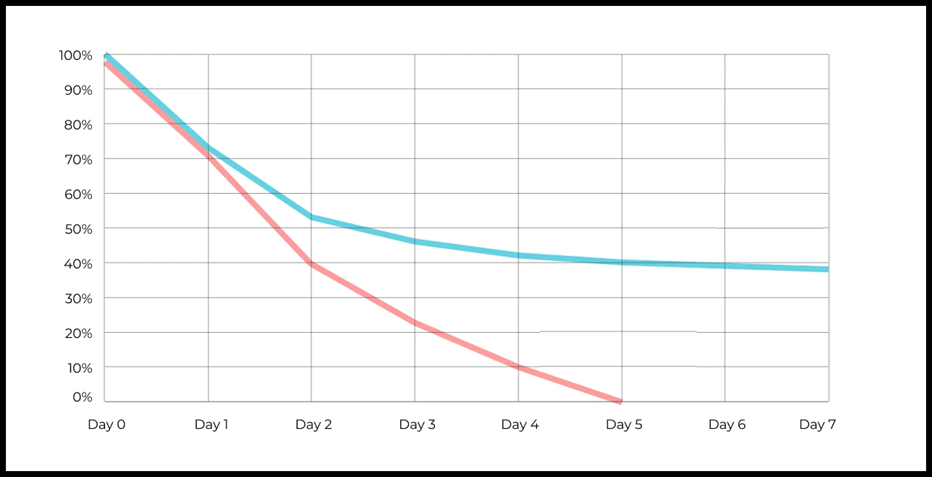!

Голубой продукт демонстрирует более высокое удержание пользователей по сравнению с красным.

У обоих продуктов наблюдается снижение Retention в первые дни, однако у голубого продукта снижение постепенно замедляется, и к 7-му дню сохраняется около 38% пользователей.

У красного продукта удержание снижается значительно быстрее и к 5-му дню достигает практически 0%.

**Вывод:** голубой продукт эффективнее удерживает пользователей и, вероятно, обладает более высокой долгосрочной ценностью для них. Красному продукту необходимо уделить внимание причинам оттока пользователей, особенно в первые 2–3 дня использования.

### 5. Во вкладке "Данные об аудитории" есть информация о том, сколько объявлений посмотрел каждый пользователь (view_adverts). Посчитайте пользовательскую конверсию в просмотр объявления за ноябрь? (в пользователях)
 #### 41,8% 
 #### 54,7% 
 #### 46,3% 
 #### 39%

In [10]:
# Отбираем данные за ноябрь
november = df[
    (df['date'] >= '2023-11-01') &
    (df['date'] < '2023-12-01')
]

# Все уникальные пользователи
total_users = november['user_id'].nunique()

# Пользователи, просмотревшие хотя бы одно объявление
viewed_users = november[
    november['view_adverts'] > 0
]['user_id'].nunique()

# Конверсия
conversion = viewed_users / total_users * 100

print('Всего пользователей:', total_users)
print('Посмотрели объявления:', viewed_users)
print(f'Конверсия: {conversion:.1f}%')

Всего пользователей: 7639
Посмотрели объявления: 3538
Конверсия: 46.3%


### 6. Используя информацию из вкладки "Данные об аудитории", посчитайте среднее количество просмотренных объявлений на пользователя в ноябре
 #### 4,9 
 #### 6,2 
 #### 5,3 
 #### 2,9

In [11]:
# Общее количество просмотров за ноябрь
total_views = november['view_adverts'].sum()

# Количество уникальных пользователей
total_users = november['user_id'].nunique()

# Среднее количество просмотров
avg_views = total_views / total_users

print('Всего просмотров:', total_views)
print('Всего пользователей:', total_users)
print(f'Среднее количество просмотров: {avg_views:.1f}')

Всего просмотров: 21914
Всего пользователей: 7639
Среднее количество просмотров: 2.9


### 7. Мы провели опрос среди 2000 пользователей. Из них 500 «критики», 1200 «сторонники» и 300 «нейтралы». Посчитайте, чему будет равен NPS 
 #### 30% 
 #### 43% 
 #### 40% 
 #### 35%

In [1]:
# Данные опроса
total_users = 2000
promoters = 1200   # Сторонники
detractors = 500   # Критики
passives = 300     # Нейтралы

# Расчет NPS
nps = (promoters / total_users - detractors / total_users) * 100

print(f'NPS: {nps:.0f}%')

NPS: 35%


### 8. Во вкладке "Данные АБ-тестов" результаты трех несвязанных АБ тестов для ARPU (общая выручка/общее количество пользователей).


In [14]:
from scipy import stats
import pandas as pd
import numpy as np

results = []

for exp in sorted(ab_users['experiment_num'].unique()):

    data = ab_users[ab_users['experiment_num'] == exp]

    control = data[data['experiment_group'] == 'control']['revenue']
    test = data[data['experiment_group'] == 'test']['revenue']

    # Средняя выручка на пользователя
    arpu_control = control.mean()
    arpu_test = test.mean()

    # Изменение ARPU в процентах
    uplift = (arpu_test / arpu_control - 1) * 100

    # T-тест Уэлча
    t_stat, p_value = stats.ttest_ind(
        control,
        test,
        equal_var=False
    )

    results.append({
        'Эксперимент': exp,
        'ARPU control': round(arpu_control, 2),
        'ARPU test': round(arpu_test, 2),
        'Uplift (%)': round(uplift, 2),
        'p-value': round(p_value, 6),
        'Значимость': 'Да' if p_value < 0.05 else 'Нет'
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Эксперимент  ARPU control  ARPU test  Uplift (%)  p-value Значимость
           1        722.46     665.74       -7.85 0.688966        Нет
           2        704.65     332.93      -52.75 0.001128         Да
           3        663.21     998.67       50.58 0.060315        Нет


### Анализ результатов A/B-тестов по метрике ARPU

Для оценки результатов трёх независимых A/B-тестов был использован t-тест Уэлча с уровнем значимости 5% (α = 0,05).

**Эксперимент №1**

- ARPU контрольной группы: 722,46
- ARPU тестовой группы: 665,74
- Изменение ARPU: −7,85%
- p-value = 0,688966

Различия между группами статистически незначимы (p-value > 0,05). Несмотря на снижение ARPU, нельзя утверждать, что тестируемое изменение действительно повлияло на выручку.

**Рекомендация:** не внедрять изменение на основании данного эксперимента, поскольку положительный эффект не подтверждён.

**Эксперимент №2**

- ARPU контрольной группы: 704,65
- ARPU тестовой группы: 332,93
- Изменение ARPU: −52,75%
- p-value = 0,001128

Полученное различие статистически значимо (p-value < 0,05). Тестируемое изменение связано со снижением средней выручки на пользователя более чем в два раза.

**Рекомендация:** отказаться от внедрения изменения, проанализировать причины снижения выручки.

**Эксперимент №3**

- ARPU контрольной группы: 663,21
- ARPU тестовой группы: 998,67
- Изменение ARPU: +50,58%
- p-value = 0,060315

ARPU тестовой группы существенно выше контрольной, однако результат не достигает статистической значимости при α = 0,05.

**Рекомендация:** провести дополнительное исследование с заранее определённым объёмом выборки, чтобы проверить устойчивость положительного эффекта.

### Общий вывод

Из трёх экспериментов только второй показал статистически значимые различия, причём в отрицательную сторону.

Первый эксперимент не продемонстрировал значимого изменения ARPU. Третий эксперимент показал потенциально положительный эффект, но статистических доказательств его эффективности пока недостаточно.

На основании полученных результатов не рекомендуется внедрять изменения из первого и второго экспериментов. Третий эксперимент заслуживает дополнительной проверки.

### 9. По датасету с листерами посчитайте средний доход на пользователя 
 #### 121.2 
 #### 156.4 
 #### 70.9 
 #### 30.7 
 #### средняя здесь не применима

In [15]:
listers = pd.read_excel(
    'test_data.xlsx',
    sheet_name='Листеры'
)

listers.head()

,user_id,date,cnt_adverts,age,cnt_contacts,revenue
0,100,2022-01-01,6,21,119,53
1,100,2022-01-02,2,21,200,18
2,100,2022-01-03,6,21,193,42
3,100,2022-01-04,2,21,143,38
4,100,2022-01-05,2,21,190,40


In [16]:
# Общая выручка
total_revenue = listers['revenue'].sum()

# Количество уникальных пользователей
total_users = listers['user_id'].nunique()

# Средний доход на пользователя
arpu = total_revenue / total_users

print('Общая выручка:', total_revenue)
print('Количество пользователей:', total_users)
print(f'Средний доход на пользователя: {arpu:.1f}')

Общая выручка: 4851
Количество пользователей: 31
Средний доход на пользователя: 156.5


### 10. По датасету с листерами посчитайте медиану возраста пользователя 
 ####  27,42 
 #### 28 
 #### 27,93 
 #### 27 
 #### медиана здесь не применима

In [18]:
unique_users = listers.drop_duplicates(subset='user_id')

median_age = unique_users['age'].median()

print('Количество пользователей:', len(unique_users))
print('Медиана возраста:', median_age)

Количество пользователей: 31
Медиана возраста: 28.0


### 11. Какой график лучше всего подходит для отображения разброса цен на товары в разных магазинах?
 ### *возможно несколько вариантов ответа 
 #### Линейный график 
 #### Круговая диаграмма 
 #### Ящик с усами (box plot)
 #### Гистограмма


Для отображения разброса цен на товары в разных магазинах лучше всего подходит ящик с усами (Box Plot), поскольку он позволяет сравнить медиану, разброс цен и выявить выбросы. Также можно использовать гистограмму, которая показывает распределение цен по интервалам и частоту их встречаемости. Линейный график и круговая диаграмма для этой задачи менее подходящие.

### 12. На каком графике бимодальное распределение
### № 1 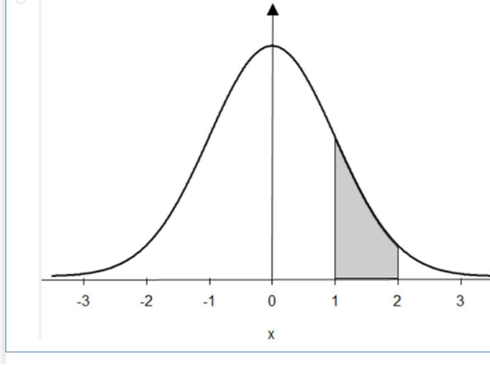
### № 2 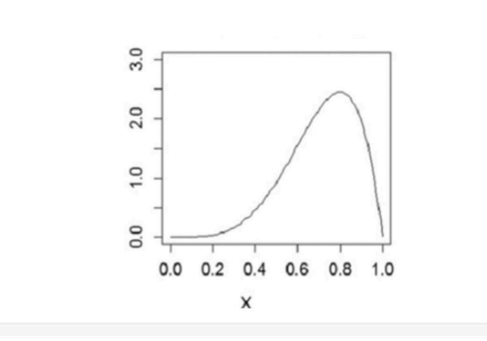
### № 3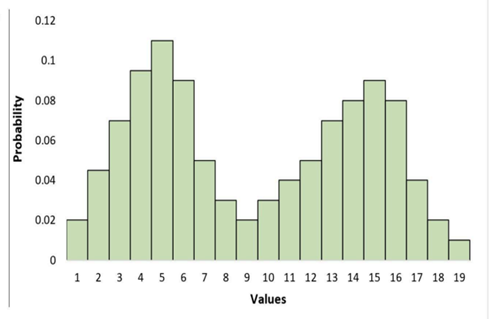
### № 4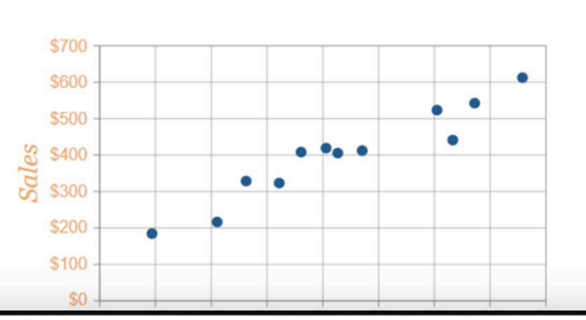

Ответ - третий график (зелёная гистограмма).
На нём изображено бимодальное распределение, поскольку оно имеет два выраженных пика (моды): примерно при значениях 5 и 15.
Бимодальное распределение может возникать, когда данные объединяют две группы с разными характеристиками.
Остальные графики не демонстрируют двух выраженных пиков.

### 13. Какая случайная величина имеет наибольшую дисперсию данных по следующим графикам плотности распределения?
### № 1 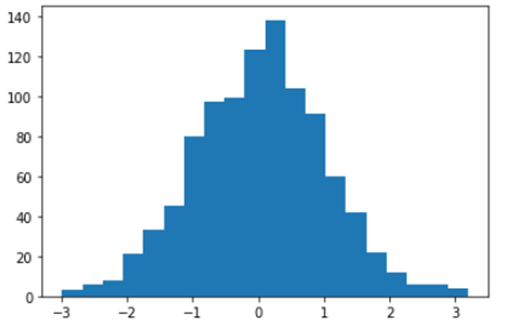
### № 2 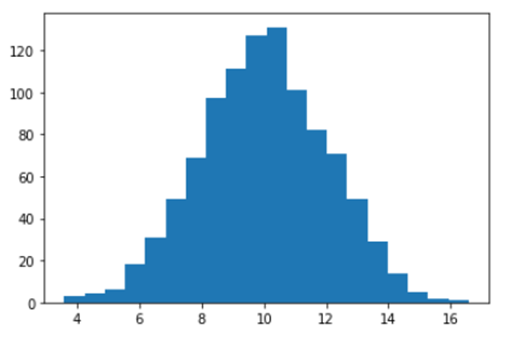
### № 3 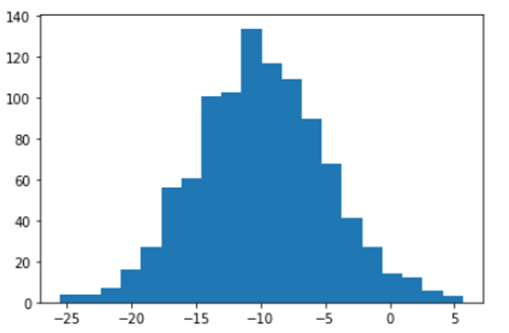
### № 4 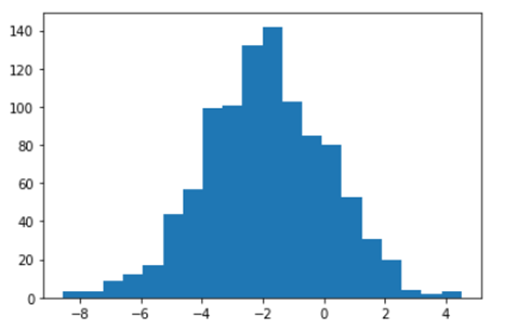

Ответ — третий график.
На третьем графике наблюдается наибольший разброс значений относительно среднего (примерно −10). Данные распределены в широком диапазоне — от −25 до +5.
Дисперсия показывает, насколько сильно значения случайной величины отклоняются от её среднего.
Чем шире распределение при сопоставимой форме, тем больше дисперсия.
Таким образом, наибольшую дисперсию имеет случайная величина на третьем графике.

### 14. На каком графике можно посчитать коррелцияю?
### *возможно несколько вариантов ответа 
### № 1 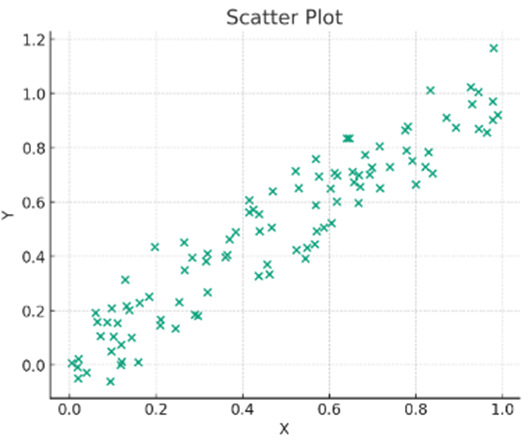
### № 2 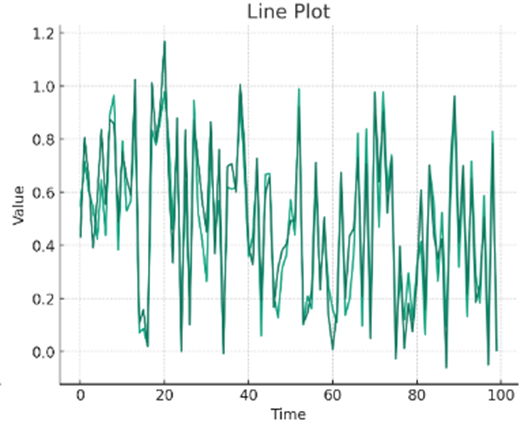
### № 3 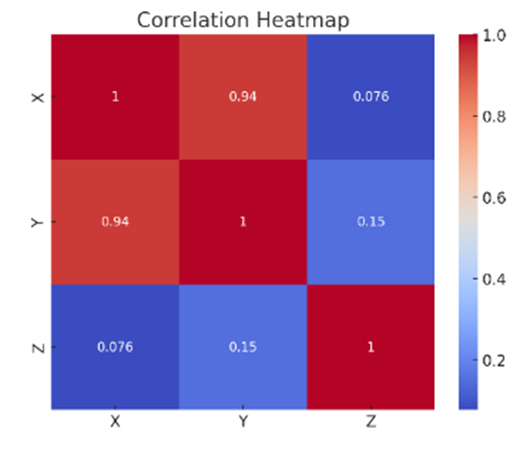
### № 4 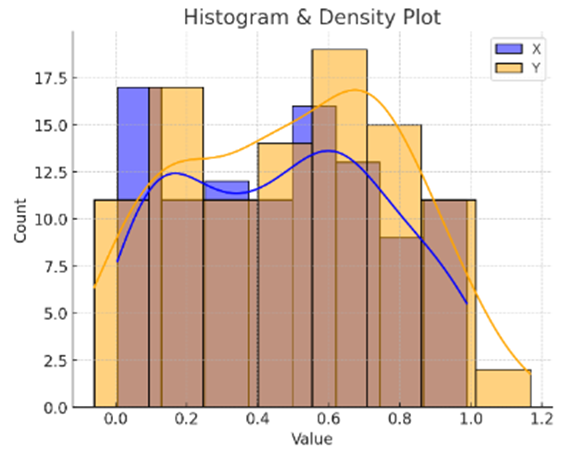

Правильные ответы — первый и третий графики.
1. Scatter Plot (диаграмма рассеяния) — позволяет визуально определить наличие, направление и силу корреляции между двумя переменными. На первом графике наблюдается сильная положительная корреляция: при увеличении X увеличивается Y.
3. Correlation Heatmap (тепловая карта корреляций) — показывает численные значения коэффициентов корреляции между переменными. Например, корреляция между X и Y составляет 0,94, что указывает на сильную положительную линейную связь.
Второй (Line Plot) и четвёртый (Histogram) графики не предназначены непосредственно для оценки корреляции между переменными.

### 15. Что значит, если при проверке гипотез мы получили p-value = 0.05? 
 #### 1. Это означает, что нет никакой статистически значимой разницы между группами
 #### 2. Есть 5% вероятность случайно получить такой или еще более экстремальный результат, если нулевая гипотеза верна
 #### 3. Это означает, что результаты эксперимента на 95% точны
 #### 4. Это говорит о том, что альтернативная гипотеза верна с вероятностью 95%

Правильный ответ — 2.
Это означает, что если нулевая гипотеза (H₀) верна, вероятность получить наблюдаемый или ещё более экстремальный результат составляет 5%.
При уровне значимости α = 0,05 результат находится на границе статистической значимости.
Важно понимать, что p-value = 0,05 не означает, что альтернативная гипотеза верна с вероятностью 95% или что результаты эксперимента точны на 95%.

### 16. Какой метод наиболее подходит для проверки гипотезы о равенстве средних двух выборок из нормального распределения?
 #### t-тест 
 #### Хи-квадрат тест 
 #### Анализ дисперсии (ANOVA) 
 #### Корреляция Пирсона

Правильный ответ — 1. t-тест (критерий Стьюдента).
T-тест используется для проверки гипотезы о равенстве средних значений двух выборок из нормально распределённых генеральных совокупностей.

### 17. Как интерпретировать квартили в распределении доходов пользователей? 
#### Показывают максимальный и минимальный доход
#### Делят данные на четыре равные части
#### Указывают на наиболее часто встречающийся доход
#### График плотности распределения вещества во вселенной

Правильный ответ — 2. Делят данные на четыре равные части.
Квартили — это значения, которые разделяют упорядоченное распределение доходов пользователей на четыре части, каждая из которых содержит примерно 25% наблюдений.
- Q1 (25-й процентиль) — 25% пользователей имеют доход не выше этого значения.
- Q2 (медиана) — 50% пользователей имеют доход не выше этого значения.
- Q3 (75-й процентиль) — 75% пользователей имеют доход не выше этого значения.
Квартили помогают оценить распределение доходов, их разброс и различия между группами пользователей.

### 18. Были получены следующие результаты. Коллеги просят вас подтвердить их и сделать окончательный вывод по эксперименту.
 #### ●	Вариант A (контрольная группа) — 100 047 501 посетитель, 1003 платежа.
 #### ●	Вариант B (тестовая группа) — 100 001 055 посетителей, 1099 платежей.
 #### Какие рекомендации вы бы дали, основываясь на этих данных?

In [19]:
from statsmodels.stats.proportion import proportions_ztest

payments = [1003, 1099]
visitors = [100047501, 100001055]

z_stat, p_value = proportions_ztest(payments, visitors)

conversion_a = payments[0] / visitors[0]
conversion_b = payments[1] / visitors[1]

uplift = (conversion_b / conversion_a - 1) * 100

print(f'Конверсия A: {conversion_a:.6%}')
print(f'Конверсия B: {conversion_b:.6%}')
print(f'Uplift: {uplift:.2f}%')
print(f'p-value: {p_value:.6f}')

Конверсия A: 0.001003%
Конверсия B: 0.001099%
Uplift: 9.62%
p-value: 0.035330


Результат:
Рост конверсии
+9,62%

p-value
0,03533



Поскольку p-value < 0,05, различие статистически значимо на уровне 5%.

По результатам A/B-тестирования конверсия в оплату в контрольной группе A составила 0,0010025%, а в тестовой группе B — 0,0010990%. Таким образом, тестовая группа показала относительный рост конверсии на 9,62%.

Для проверки статистической значимости использован Z-тест пропорций. Полученное значение p-value = 0,03533, что меньше уровня значимости 0,05. Следовательно, различия между группами статистически значимы.

Однако абсолютная конверсия в обеих группах крайне низкая, поэтому перед окончательным внедрением изменений необходимо проверить корректность данных, уникальность посетителей, методику подсчёта платежей и качество рандомизации.

**Рекомендация:** при подтверждении корректности эксперимента рассмотреть внедрение варианта B, предварительно оценив экономическую выгоду, влияние на выручку и другие ключевые метрики.